# Chapter 3 — Exercises 9 and 14
### Group Assignment: Linear Regression

**Question 9** uses the `Auto` dataset for multiple linear regression, diagnostics, interactions, and transformations.

**Question 14** explores the collinearity problem using simulated data.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF
from ISLP import load_data
from ISLP.models import ModelSpec as MS, summarize, poly

---
# Question 9

*This question involves the use of multiple linear regression on the `Auto` data set.*


In [2]:
Auto = load_data('Auto')
Auto.shape

(392, 8)

## (a) Scatterplot matrix

*Produce a scatterplot matrix which includes all of the variables in the data set.*

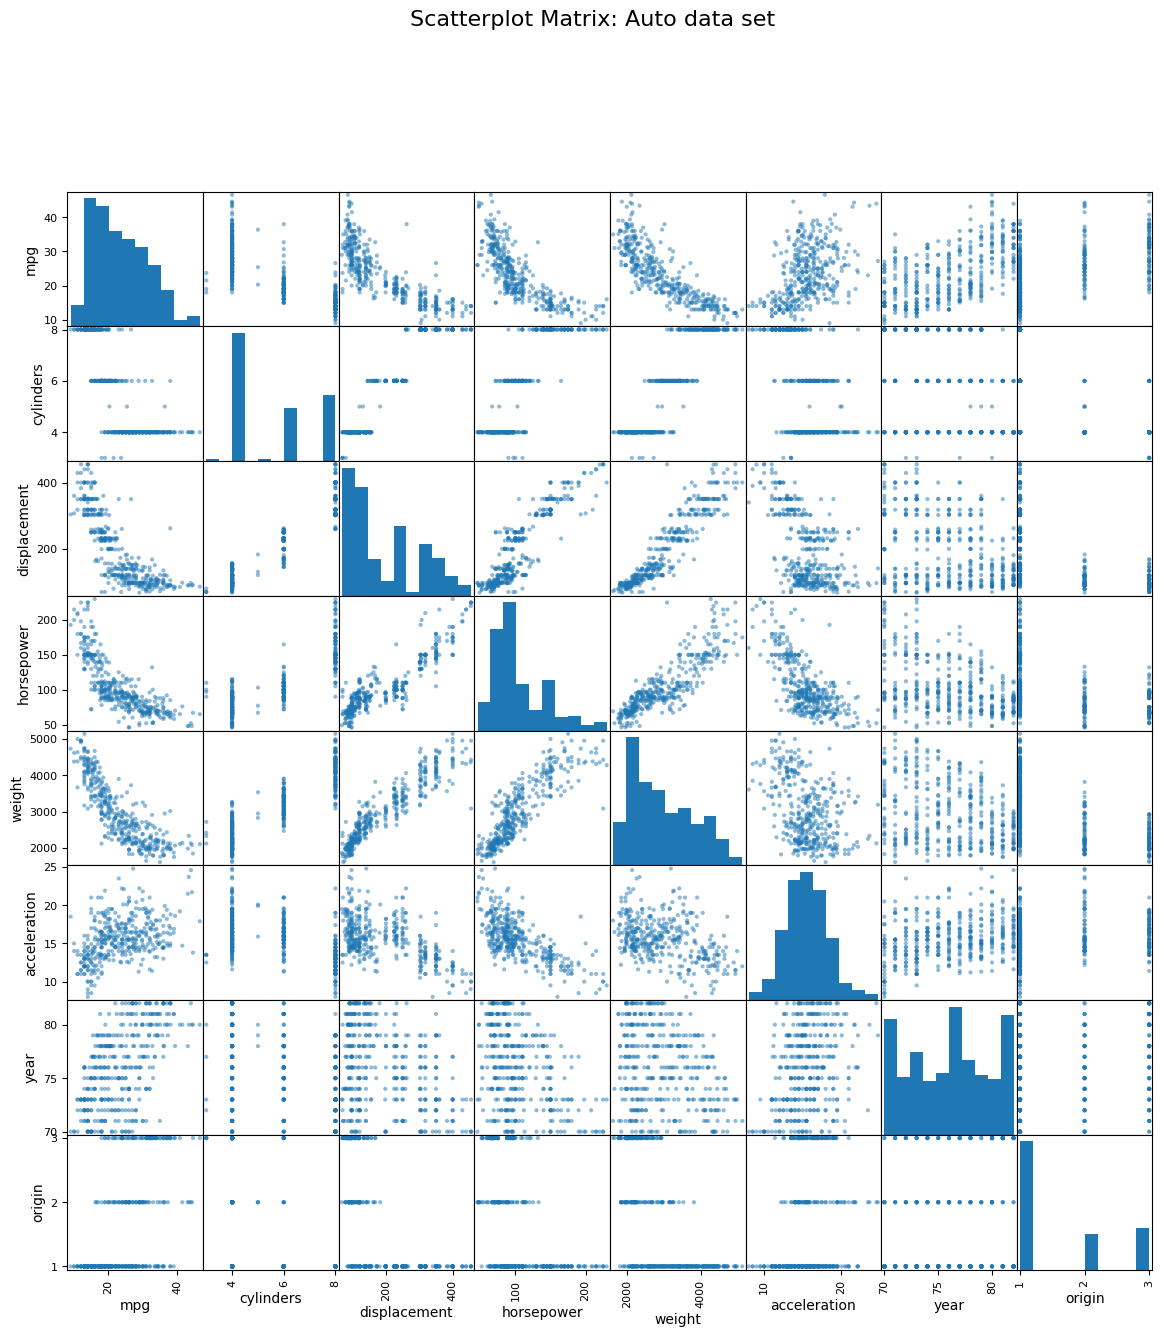

In [3]:
fig = pd.plotting.scatter_matrix(Auto, figsize=(14, 14), diagonal='hist')
plt.suptitle('Scatterplot Matrix: Auto data set', y=1.01, fontsize=16)
plt.show()

## (b) Correlation matrix

*Compute the matrix of correlations between the variables using the `DataFrame.corr()` method. Note: `name` is qualitative and is excluded — in this version of the `Auto` data, `name` is actually the DataFrame's row index, so `.corr(numeric_only=True)` naturally excludes it.*

In [4]:
corr_matrix = Auto.corr(numeric_only=True)
corr_matrix.round(3)

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
mpg,1.000,-0.778,-0.805,-0.778,-0.832,0.423,0.581,0.565
cylinders,-0.778,1.000,0.951,0.843,0.898,-0.505,-0.346,-0.569
displacement,-0.805,0.951,1.000,0.897,0.933,-0.544,-0.370,-0.615
horsepower,-0.778,0.843,0.897,1.000,0.865,-0.689,-0.416,-0.455
weight,-0.832,0.898,0.933,0.865,1.000,-0.417,-0.309,-0.585
acceleration,0.423,-0.505,-0.544,-0.689,-0.417,1.000,0.290,0.213
year,0.581,-0.346,-0.370,-0.416,-0.309,0.290,1.000,0.182
origin,0.565,-0.569,-0.615,-0.455,-0.585,0.213,0.182,1.000


## (c) Multiple linear regression

*Use `sm.OLS()` to perform a multiple linear regression with `mpg` as the response and all other variables except `name` as the predictors.*

In [5]:
X = MS(Auto.columns.drop('mpg')).fit_transform(Auto)
y = Auto['mpg']
model_full = sm.OLS(y, X).fit()
summarize(model_full)

,coef,std err,t,P>|t|
intercept,-17.2184,4.644,-3.707,0.000
cylinders,-0.4934,0.323,-1.526,0.128
displacement,0.0199,0.008,2.647,0.008
horsepower,-0.0170,0.014,-1.230,0.220
weight,-0.0065,0.001,-9.929,0.000
acceleration,0.0806,0.099,0.815,0.415
year,0.7508,0.051,14.729,0.000
origin,1.4261,0.278,5.127,0.000


In [6]:
print(f"R-squared: {model_full.rsquared:.4f}")
print(f"F-statistic: {model_full.fvalue:.2f}   p-value: {model_full.f_pvalue:.3e}")

R-squared: 0.8215
F-statistic: 252.43   p-value: 2.037e-139


**Comments on the output:**

**i. Is there a relationship between the predictors and the response?**
Yes — the overall F-statistic is very large (≈252) with an essentially zero p-value, so we reject the null hypothesis that all coefficients (except the intercept) are zero. There is strong evidence of a relationship between the predictors, collectively, and `mpg`.

**ii. Which predictors appear to have a statistically significant relationship to the response?**
Looking at the individual p-values (`P>|t|`), `displacement`, `weight`, `year`, and `origin` all have p-values well below 0.05 and are statistically significant. `cylinders`, `horsepower`, and `acceleration` do **not** appear individually significant at the 5% level once the other predictors are already in the model — likely because they are highly correlated with `displacement` and `weight` (see the correlation matrix above), so their individual contribution is masked by multicollinearity.

**iii. What does the coefficient for the `year` variable suggest?**
The coefficient on `year` is about **0.75**, meaning that, holding all other predictors fixed, `mpg` increases by roughly 0.75 miles per gallon for each additional model year. This reflects the trend of cars becoming more fuel-efficient over time in this dataset.

## (d) Diagnostic plots

*Produce diagnostic plots of the linear regression fit. Comment on any problems, unusually large outliers, and high-leverage points.*

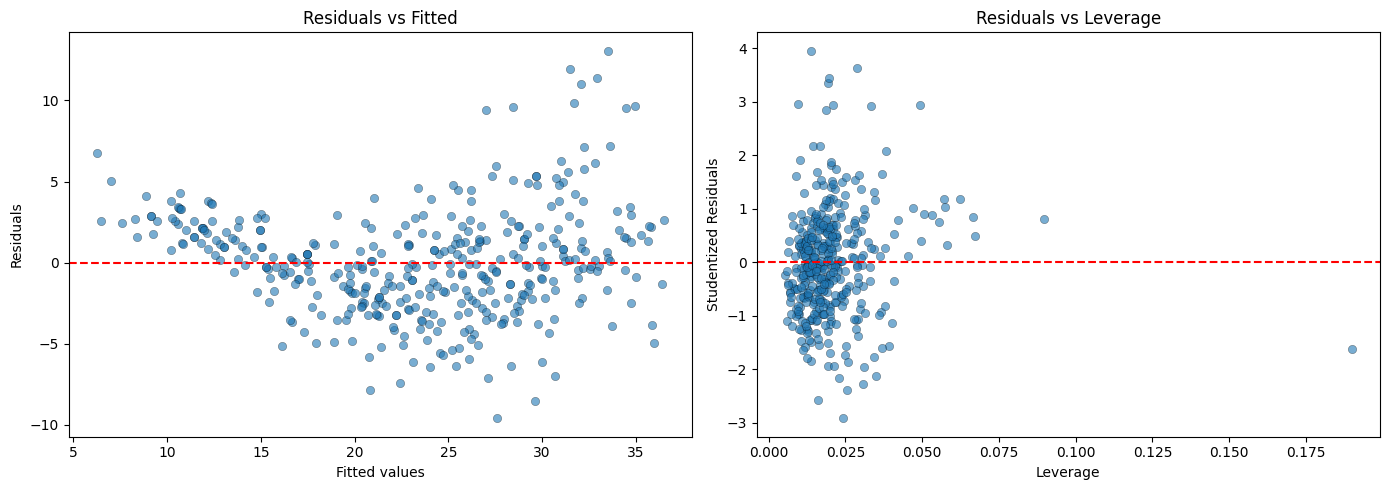

In [7]:
fitted = model_full.fittedvalues
resid = model_full.resid
influence = model_full.get_influence()
leverage = influence.hat_matrix_diag
student_resid = influence.resid_studentized_internal

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(fitted, resid, alpha=0.6, edgecolor='k', linewidth=0.3)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

axes[1].scatter(leverage, student_resid, alpha=0.6, edgecolor='k', linewidth=0.3)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Leverage')
axes[1].set_ylabel('Studentized Residuals')
axes[1].set_title('Residuals vs Leverage')

plt.tight_layout()
plt.show()

In [8]:
# Identify the highest-leverage observations
high_leverage_idx = np.argsort(leverage)[-5:][::-1]
Auto.iloc[high_leverage_idx].assign(leverage=leverage[high_leverage_idx])

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,leverage
name,,,,,,,,,
buick estate wagon (sw),14.0,8,455.0,225,3086,10.0,70,1,0.189913
hi 1200d,9.0,8,304.0,193,4732,18.5,70,1,0.089541
chevy c20,10.0,8,307.0,200,4376,15.0,70,1,0.067370
dodge d200,11.0,8,318.0,210,4382,13.5,70,1,0.066673
pontiac catalina,14.0,8,455.0,225,4425,10.0,70,1,0.062449


**Comments:**

- The **residuals vs. fitted** plot shows a mild funnel/curved pattern rather than a random cloud of points — residuals are more spread out at low and high fitted values, and there's a slight U-shape. This suggests some **non-linearity** in the relationship between the predictors and `mpg` that a straight-line model doesn't fully capture (a classic pattern that motivates transformations, done below in part (f)).
- The **residuals vs. leverage** plot shows a small number of points with noticeably higher leverage than the rest (leverage roughly 0.15–0.19, well above the average leverage of $p/n \approx 8/392 \approx 0.02$). These tend to correspond to cars with unusual combinations of predictors (e.g., very high `horsepower`/`weight` for their `displacement`). None of them have extremely large studentized residuals at the same time, so they're high-leverage but not necessarily highly influential outliers — still worth flagging for further investigation.

## (e) Interaction effects

*Fit linear regression models with interaction effects. Do any interactions appear to be statistically significant?*

We try a `weight:horsepower` interaction, since both are strongly correlated with `mpg` and with each other.

In [9]:
X_int = MS(['weight', 'horsepower', ('weight', 'horsepower')]).fit_transform(Auto)
model_int = sm.OLS(y, X_int).fit()
summarize(model_int)

,coef,std err,t,P>|t|
intercept,63.557900,2.343000,27.127,0.0
weight,-0.010800,0.001000,-13.921,0.0
horsepower,-0.250800,0.027000,-9.195,0.0
weight:horsepower,0.000054,0.000007,8.054,0.0


In [10]:
print(f"R-squared (weight*horsepower interaction model): {model_int.rsquared:.4f}")
print(f"R-squared (full additive model):                    {model_full.rsquared:.4f}")

R-squared (weight*horsepower interaction model): 0.7484
R-squared (full additive model):                    0.8215


**Comment:** The `weight:horsepower` interaction term is **highly statistically significant** (p < 0.001), meaning the effect of `horsepower` on `mpg` depends on the car's `weight` (and vice versa) — heavier cars see a different marginal effect of horsepower than lighter cars. This two-variable interaction model alone achieves an $R^2$ of about 0.75, not far off from the 8-variable additive model's 0.82, showing this interaction captures a substantial amount of the signal in the data.

## (f) Variable transformations

*Try a few different transformations of the variables, such as $\log(X)$, $\sqrt{X}$, $X^2$. Comment on your findings.*

We try these transformations on `horsepower`, since the residual plot in (d) hinted at non-linearity, and `horsepower` is a natural candidate.

In [11]:
# Linear (baseline)
X_lin = MS(['horsepower']).fit_transform(Auto)
m_lin = sm.OLS(y, X_lin).fit()

# log(horsepower)
Auto_log = Auto.assign(log_horsepower=np.log(Auto['horsepower']))
X_log = MS(['log_horsepower']).fit_transform(Auto_log)
m_log = sm.OLS(y, X_log).fit()

# sqrt(horsepower)
Auto_sqrt = Auto.assign(sqrt_horsepower=np.sqrt(Auto['horsepower']))
X_sqrt = MS(['sqrt_horsepower']).fit_transform(Auto_sqrt)
m_sqrt = sm.OLS(y, X_sqrt).fit()

# horsepower^2 (quadratic)
X_poly2 = MS([poly('horsepower', degree=2)]).fit_transform(Auto)
m_poly2 = sm.OLS(y, X_poly2).fit()

pd.DataFrame({
    'Model': ['mpg ~ horsepower', 'mpg ~ log(horsepower)', 'mpg ~ sqrt(horsepower)', 'mpg ~ horsepower + horsepower^2'],
    'R-squared': [m_lin.rsquared, m_log.rsquared, m_sqrt.rsquared, m_poly2.rsquared]
})

,Model,R-squared
0,mpg ~ horsepower,0.605948
1,mpg ~ log(horsepower),0.668335
2,mpg ~ sqrt(horsepower),0.643704
3,mpg ~ horsepower + horsepower^2,0.687559


In [12]:
summarize(m_poly2)

,coef,std err,t,P>|t|
intercept,23.4459,0.221,106.130,0.0
"poly(horsepower, degree=2)[0]",-120.1377,4.374,-27.467,0.0
"poly(horsepower, degree=2)[1]",44.0895,4.374,10.080,0.0


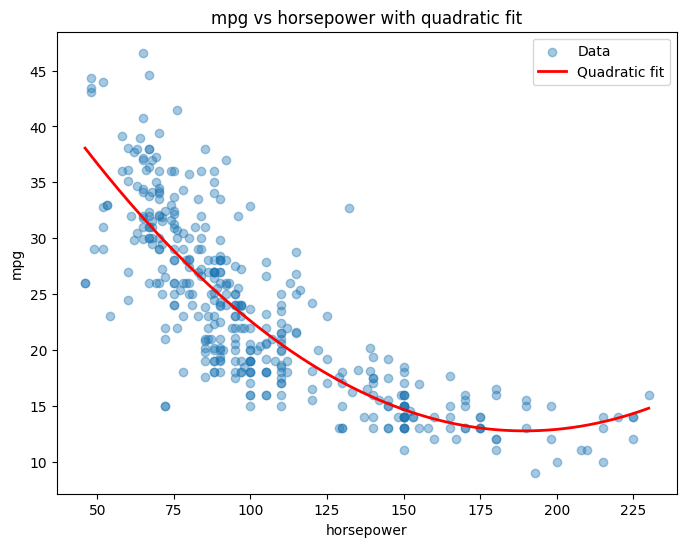

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Auto['horsepower'], Auto['mpg'], alpha=0.4, label='Data')

hp_grid = pd.DataFrame({'horsepower': np.linspace(Auto['horsepower'].min(), Auto['horsepower'].max(), 200)})
Xg = MS([poly('horsepower', degree=2)]).fit(Auto).transform(hp_grid)
pred = m_poly2.get_prediction(Xg).predicted_mean
ax.plot(hp_grid['horsepower'], pred, color='red', linewidth=2, label='Quadratic fit')

ax.set_xlabel('horsepower')
ax.set_ylabel('mpg')
ax.set_title('mpg vs horsepower with quadratic fit')
ax.legend()
plt.show()

**Comment:** All three transformations improve on the plain linear fit ($R^2 = 0.606$ for `mpg ~ horsepower` alone):

| Transformation | $R^2$ |
|---|---|
| Linear | ~0.606 |
| $\log(\text{horsepower})$ | ~0.668 |
| $\sqrt{\text{horsepower}}$ | ~0.644 |
| $\text{horsepower} + \text{horsepower}^2$ | ~0.688 |

The quadratic fit gives the best improvement here, and both the `horsepower` and `horsepower²` terms are highly significant, confirming a genuine curved (non-linear) relationship rather than a straight line — consistent with the funnel/curve pattern spotted in the residual plot in part (d). Physically this makes sense: fuel efficiency drops off faster than linearly as horsepower increases beyond a certain point.

---
# Question 14

*This problem focuses on the collinearity problem.*


## (a) Generate the simulated data

*Perform the following in Python and write out the form of the linear model. What are the regression coefficients?*

In [14]:
rng = np.random.default_rng(10)
x1 = rng.uniform(0, 1, size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)

df14 = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y})
df14.head()

,x1,x2,y
0,0.956002,0.469359,4.356977
1,0.207682,0.142509,3.677789
2,0.828445,0.587699,3.482079
3,0.149282,0.181141,2.369093
4,0.512805,0.236458,1.413295


**The linear model is:**
$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \epsilon$$

with true (population) regression coefficients $\beta_0 = 2$, $\beta_1 = 2$, and $\beta_2 = 0.3$. Note that `x2` is itself constructed as a (noisy) linear function of `x1`, which is exactly what creates the collinearity we'll investigate below.

## (b) Correlation between x1 and x2

*What is the correlation between `x1` and `x2`? Create a scatterplot displaying the relationship between the variables.*

In [15]:
corr_x1x2 = np.corrcoef(x1, x2)[0, 1]
print(f"Correlation between x1 and x2: {corr_x1x2:.4f}")

Correlation between x1 and x2: 0.7723


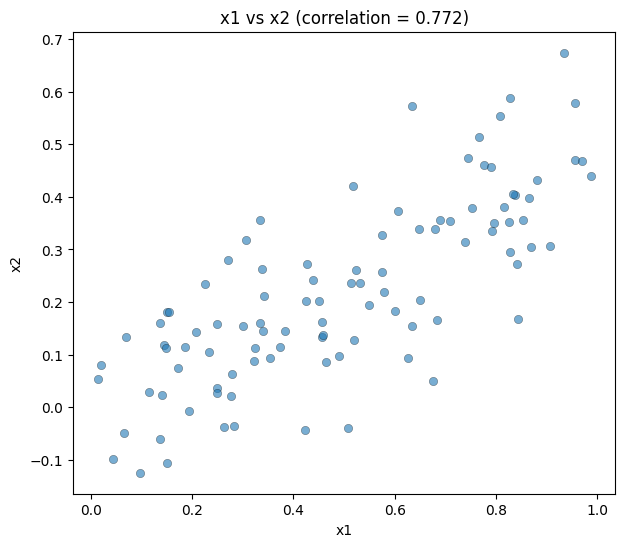

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(x1, x2, alpha=0.6, edgecolor='k', linewidth=0.3)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title(f'x1 vs x2 (correlation = {corr_x1x2:.3f})')
plt.show()

`x1` and `x2` are **strongly correlated** (r ≈ 0.77) — as expected, since `x2` was built directly from `x1` plus a smaller noise term. This is exactly the setup for a collinearity problem.

## (c) Regress y on both x1 and x2

*Fit a least squares regression to predict `y` using `x1` and `x2`. Describe the results. What are $\hat\beta_0$, $\hat\beta_1$, $\hat\beta_2$? Can you reject $H_0: \beta_1 = 0$? $H_0: \beta_2 = 0$?*

In [17]:
X_both = MS(['x1', 'x2']).fit_transform(df14)
model_both = sm.OLS(y, X_both).fit()
summarize(model_both)

,coef,std err,t,P>|t|
intercept,1.9579,0.190,10.319,0.000
x1,1.6154,0.527,3.065,0.003
x2,0.9428,0.831,1.134,0.259


**Results:** $\hat\beta_0 \approx 1.96$, $\hat\beta_1 \approx 1.62$, $\hat\beta_2 \approx 0.94$.

Compared to the true values ($\beta_0=2$, $\beta_1=2$, $\beta_2=0.3$): $\hat\beta_0$ is close to the truth, but $\hat\beta_1$ is noticeably *underestimated* and $\hat\beta_2$ is wildly *overestimated* — a classic symptom of collinearity. When two predictors are highly correlated, least squares has difficulty separating their individual effects, so the estimated coefficients become unstable and can be far from their true values even though the *combined* fit may still be reasonable.

- $H_0: \beta_1 = 0$ — the p-value for `x1` is about 0.003, well below 0.05, so we **reject** $H_0$: there is significant evidence `x1` has a nonzero effect.
- $H_0: \beta_2 = 0$ — the p-value for `x2` is about 0.26, well above 0.05, so we **cannot reject** $H_0$: we do not have significant evidence that `x2` has a nonzero effect *once `x1` is already in the model*.

## (d) Regress y on x1 only

*Fit a least squares regression to predict `y` using only `x1`. Can you reject $H_0: \beta_1 = 0$?*

In [18]:
X_x1 = MS(['x1']).fit_transform(df14)
model_x1 = sm.OLS(y, X_x1).fit()
summarize(model_x1)

,coef,std err,t,P>|t|
intercept,1.9371,0.189,10.242,0.0
x1,2.0771,0.335,6.196,0.0


**Result:** $\hat\beta_1 \approx 2.08$, very close to the true value of 2, with a p-value effectively 0. We can **strongly reject** $H_0: \beta_1=0$ — with `x2` removed from the model, `x1` alone is a highly significant and much more accurately-estimated predictor of `y`.

## (e) Regress y on x2 only

*Fit a least squares regression to predict `y` using only `x2`. Can you reject $H_0: \beta_1 = 0$ (i.e., the coefficient on `x2`)?*

In [19]:
X_x2 = MS(['x2']).fit_transform(df14)
model_x2 = sm.OLS(y, X_x2).fit()
summarize(model_x2)

,coef,std err,t,P>|t|
intercept,2.3239,0.154,15.124,0.0
x2,2.9103,0.550,5.291,0.0


**Result:** $\hat\beta \approx 2.91$ for `x2` — far from its true value of 0.3! — but with a p-value effectively 0. So we can **strongly reject** the null that this coefficient is zero, even though `x2`'s true effect on `y` is small (0.3). This happens because `x2` is highly correlated with `x1`, so on its own `x2` is picking up much of `x1`'s real effect on `y` — it's acting as a (noisy) **proxy** for `x1`.

## (f) Do the results from (c)–(e) contradict each other?

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

vif_vals = [VIF(X_both, i) for i in range(1, X_both.shape[1])]
pd.DataFrame({'variable': ['x1', 'x2'], 'VIF': vif_vals})

,variable,VIF
0,x1,2.478223
1,x2,2.478223


**No, these results do not actually contradict each other — they illustrate exactly what collinearity does.**

- When `x1` and `x2` are both in the model together, they compete to explain the same overlapping variation in `y` (since they're correlated with each other), inflating their standard errors and making it hard for the regression to tell which one is "really" driving `y`. This is why `x2`'s effect looked statistically insignificant in part (c) — not because `x2` has no relationship with `y`, but because once `x1` is already accounting for the shared variation, there's little *additional, distinguishable* signal left for `x2` to explain.
- When each predictor is used **alone** (parts (d) and (e)), it's no longer competing with a correlated partner, so it can "absorb" all of the shared explanatory power — including the portion that rightfully belongs to the other variable. That's why `x2` alone appears so strongly significant with an inflated coefficient (≈2.91 instead of the true 0.3): it's borrowing explanatory power that actually came through `x1`.
- The VIF values above (~2.5 for both predictors) confirm the presence of meaningful multicollinearity, consistent with the moderate-to-high correlation (r ≈ 0.77) we found in part (b).

**Bottom line:** collinearity doesn't make any of these individual regressions "wrong" — each is a mathematically valid least-squares fit — but it does mean that the *individual* coefficient estimates and significance tests from the multiple regression in (c) should be interpreted cautiously, since collinearity inflates standard errors and can mask or misattribute the true effect of correlated predictors.